# Part 4 — Generative AI: structuring follow-up notes and building front-desk recommendations
**Goal:** call-center staff write free-text notes after phoning patients who missed an appointment. We use the **Gemini API** (free tier) with a **Pydantic schema** to turn the **first 10 notes** into structured fields, then combine them with the **ML risk scores from Part 3** into a prioritised call list for the front desk.

**Setup (free):**
1. Create a free key in [Google AI Studio](https://aistudio.google.com/apikey)
2. Copy `.env.example` to `.env` and set `GEMINI_API_KEY=...` (`.env` is git-ignored — **never commit a key**)
3. `pip install google-genai python-dotenv pydantic`

**No key? No problem.** If no key (or no `google-genai` package) is found, the notebook falls back to a transparent **rule-based extractor that fills the very same schema**, so the whole pipeline still runs. Every output row records which engine produced it (`extraction_source`). Re-run with a key to get real Gemini output.

In [1]:
import os
import re
import time
from enum import Enum
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field

try:
    from dotenv import load_dotenv
    load_dotenv("../.env")
except ImportError:
    pass

SEED = 42
np.random.seed(SEED)
DATA, OUT = Path("../data"), Path("../outputs")
(OUT / "figures").mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)

GEMINI_API_KEY = os.getenv("GEMINI_API_KEY", "").strip()
if GEMINI_API_KEY.startswith("your_"):
    GEMINI_API_KEY = ""
GEMINI_MODEL = os.getenv("GEMINI_MODEL", "gemini-2.5-flash")
try:
    from google import genai
    from google.genai import types
    HAVE_SDK = True
except ImportError:
    HAVE_SDK = False
USE_GEMINI = bool(GEMINI_API_KEY) and HAVE_SDK
print("ENGINE:", f"Gemini ({GEMINI_MODEL})" if USE_GEMINI else
      f"rule-based fallback  (key set: {bool(GEMINI_API_KEY)}, google-genai installed: {HAVE_SDK})")

ENGINE: rule-based fallback  (key set: False, google-genai installed: True)


## 1. The Pydantic schema
Enums force the model to choose from a fixed list, which makes the output easy to count, filter and join. Pydantic also **validates** every response, so a malformed answer fails loudly instead of silently polluting the data.

In [2]:
class NoShowReason(str, Enum):
    TRANSPORT = "transport"
    WORK_CONFLICT = "work_conflict"
    FORGOT = "forgot"
    FELT_BETTER = "felt_better"
    COST_OR_INSURANCE = "cost_or_insurance"
    ILLNESS = "illness"
    FAMILY_EMERGENCY = "family_emergency"
    WEATHER = "weather"
    CHILDCARE = "childcare"
    OTHER_OR_UNKNOWN = "other_or_unknown"

class PreferredTime(str, Enum):
    MORNING = "morning"
    AFTERNOON = "afternoon"
    EVENING = "evening"
    WEEKEND = "weekend"
    NO_PREFERENCE = "no_preference"

class Sentiment(str, Enum):
    POSITIVE = "positive"
    NEUTRAL = "neutral"
    NEGATIVE = "negative"

class FollowUpExtraction(BaseModel):
    primary_reason: NoShowReason = Field(description="Main reason the patient missed the appointment")
    wants_to_reschedule: bool = Field(description="True only if the patient asked for or agreed to a new appointment")
    preferred_time: PreferredTime = Field(description="Preferred time of day for the new slot, if stated")
    patient_sentiment: Sentiment = Field(description="Patient's tone during the call")
    urgent_medical_concern: bool = Field(description="True if the PATIENT has a serious or worsening medical problem that needs a clinical call-back")
    summary: str = Field(description="One short sentence (max 25 words) summarising the call")

import json
print(json.dumps(FollowUpExtraction.model_json_schema()["properties"], indent=1)[:700], "...")

{
 "primary_reason": {
  "$ref": "#/$defs/NoShowReason",
  "description": "Main reason the patient missed the appointment"
 },
 "wants_to_reschedule": {
  "description": "True only if the patient asked for or agreed to a new appointment",
  "title": "Wants To Reschedule",
  "type": "boolean"
 },
 "preferred_time": {
  "$ref": "#/$defs/PreferredTime",
  "description": "Preferred time of day for the new slot, if stated"
 },
 "patient_sentiment": {
  "$ref": "#/$defs/Sentiment",
  "description": "Patient's tone during the call"
 },
 "urgent_medical_concern": {
  "description": "True if the PATIENT has a serious or worsening medical problem that needs a clinical call-back",
  "title": "Urgent Me ...


## 2. Extraction engines
**Gemini** is asked for JSON that matches the schema (`response_schema`), at temperature 0 for repeatable output, and the reply is validated by Pydantic. A small retry loop handles free-tier rate limits.

In [3]:
SYSTEM_PROMPT = (
    "You are an assistant for the call-center team of CareClick Clinics. You read a short note that a call-center "
    "agent wrote after phoning a patient who missed an appointment, and you extract structured facts. "
    "Use only what the note says; if something is not stated, choose the neutral option "
    "(other_or_unknown, no_preference, wants_to_reschedule=false). Mark urgent_medical_concern=true only when the "
    "patient themself has a serious or worsening condition.")

def extract_with_gemini(note_text: str, retries: int = 4) -> FollowUpExtraction:
    client = genai.Client(api_key=GEMINI_API_KEY)
    config = types.GenerateContentConfig(
        system_instruction=SYSTEM_PROMPT, response_mime_type="application/json",
        response_schema=FollowUpExtraction, temperature=0.0)
    for attempt in range(retries):
        try:
            resp = client.models.generate_content(model=GEMINI_MODEL, contents=f"Call note:\n{note_text}", config=config)
            return FollowUpExtraction.model_validate_json(resp.text)
        except Exception as exc:
            if attempt == retries - 1:
                raise
            wait = 5 * 2 ** attempt
            print(f"  Gemini call failed ({type(exc).__name__}); retrying in {wait}s")
            time.sleep(wait)

**Fallback:** keyword rules (ordered, most specific first). It is deliberately simple — good enough to keep the pipeline runnable, not a replacement for an LLM.

In [4]:
REASON_RULES = [
    (NoShowReason.FAMILY_EMERGENCY, ["father", "mother had a", "death in the family", "family emergency"]),
    (NoShowReason.ILLNESS, ["fever", "vomit", "flu", "body ache", "chest pain", "admitted"]),
    (NoShowReason.WEATHER, ["rain", "waterlogging", "heat", "storm"]),
    (NoShowReason.CHILDCARE, ["kids", "childcare", "school pickup", "look after"]),
    (NoShowReason.COST_OR_INSURANCE, ["fee", "insurance", "self-pay", "price", "cost"]),
    (NoShowReason.WORK_CONFLICT, ["meeting", "boss", "office", "work trip", "refused leave"]),
    (NoShowReason.FORGOT, ["forgot", "lost track", "mixed up", "did not see the reminder"]),
    (NoShowReason.TRANSPORT, ["bus", "metro", "auto-rickshaw", "traffic", "strike", "road accident"]),
    (NoShowReason.FELT_BETTER, ["went away", "felt much better", "felt better", "symptoms"]),
]
NO_RESCHEDULE = ["no need to rebook", "does not want to", "did not ask to rebook", "no rebooking", "will contact us",
                 "will let us know", "will call if", "call back later"]
WANT_RESCHEDULE = ["rebook", "reschedule", "new slot", "a slot", "slot", "book"]
PREF_CUES = ["slot", "prefer", "best", "works", "wants", "asked", "needs", "rebook"]

def extract_rule_based(note_text: str) -> FollowUpExtraction:
    t = note_text.lower()
    reason = next((r for r, kws in REASON_RULES if any(k in t for k in kws)), NoShowReason.OTHER_OR_UNKNOWN)
    wants = any(k in t for k in WANT_RESCHEDULE) and not any(k in t for k in NO_RESCHEDULE)
    pref = " ".join(s for s in re.split(r"(?<=[.!?])\s+", t) if any(c in s for c in PREF_CUES))
    if "weekend" in pref or "saturday" in pref:
        when = PreferredTime.WEEKEND
    elif "evening" in pref or "6pm" in pref:
        when = PreferredTime.EVENING
    elif "morning" in pref:
        when = PreferredTime.MORNING
    elif "afternoon" in pref or "after school" in pref:
        when = PreferredTime.AFTERNOON
    else:
        when = PreferredTime.NO_PREFERENCE
    negative = any(k in t for k in ["frustrated", "upset", "stressed", "angry"])
    urgent = any(k in t for k in ["chest pain", "admitted", "severe"])
    label = reason.value.replace("_", " ")
    return FollowUpExtraction(
        primary_reason=reason, wants_to_reschedule=wants, preferred_time=when,
        patient_sentiment=Sentiment.NEGATIVE if negative else Sentiment.NEUTRAL, urgent_medical_concern=urgent,
        summary=f"Missed visit due to {label}; " + ("wants to rebook" + (f" ({when.value})" if when != PreferredTime.NO_PREFERENCE else "")
                                                  if wants else "not asking to rebook") + ".")

extract = extract_with_gemini if USE_GEMINI else extract_rule_based
SOURCE = f"gemini:{GEMINI_MODEL}" if USE_GEMINI else "rule_based_fallback"

## 3. Run on the first 10 follow-up notes

In [5]:
notes = pd.read_csv(DATA / "follow_up_notes.csv")
first10 = notes.head(10).copy()
print(f"{len(notes)} notes in the file; processing the first {len(first10)}")

records = []
for _, r in first10.iterrows():
    result = extract(r["note_text"])
    records.append({"note_id": r["note_id"], "appointment_id": r["appointment_id"], **result.model_dump(mode="json"),
                    "extraction_source": SOURCE})
    if USE_GEMINI:
        time.sleep(4.5)
structured = pd.DataFrame(records)
structured.to_csv(OUT / "followup_notes_structured.csv", index=False)
structured[["note_id", "appointment_id", "primary_reason", "wants_to_reschedule", "preferred_time",
            "patient_sentiment", "urgent_medical_concern"]]

40 notes in the file; processing the first 10


,note_id,appointment_id,primary_reason,wants_to_reschedule,preferred_time,patient_sentiment,urgent_medical_concern
0,N001,1000783,weather,True,morning,neutral,False
1,N002,1004878,transport,True,no_preference,neutral,False
2,N003,1009978,family_emergency,True,no_preference,negative,False
3,N004,1000291,other_or_unknown,False,no_preference,neutral,False
4,N005,1005413,work_conflict,True,evening,neutral,False
5,N006,1000801,felt_better,False,no_preference,neutral,False
6,N007,1004342,transport,True,no_preference,neutral,False
7,N008,1010176,family_emergency,False,no_preference,neutral,False
8,N009,1009154,cost_or_insurance,True,no_preference,negative,False
9,N010,1000966,forgot,True,no_preference,neutral,False


In [6]:
pd.concat([first10[["note_id", "note_text"]].set_index("note_id"), structured.set_index("note_id")[["summary"]]], axis=1)

,note_text,summary
note_id,,
N001,Pt says the extreme heat made her avoid travelling in the afternoon. Wants an early mo...,Missed visit due to weather; wants to rebook (morning).
N002,"Spoke to pt - auto-rickshaw never showed up and the metro was down. Apologetic, would ...",Missed visit due to transport; wants to rebook.
N003,"Patient's father had a medical emergency, so they rushed to the hospital. Very stresse...",Missed visit due to family emergency; wants to rebook.
N004,"Patient did not give a clear reason, call was short. Did not ask to rebook.",Missed visit due to other or unknown; not asking to rebook.
N005,Patient got pulled into an urgent meeting at the office and could not leave. Asked for...,Missed visit due to work conflict; wants to rebook (evening).
N006,Patient says symptoms went away on their own so they did not come. No need to rebook f...,Missed visit due to felt better; not asking to rebook.
N007,"Pt stuck in heavy traffic after a road accident near the clinic, gave up and went home...",Missed visit due to transport; wants to rebook.
N008,Pt had a death in the family and travelled out of town. Will contact us when back.,Missed visit due to family emergency; not asking to rebook.
N009,"Patient worried about the consultation fee and unsure if insurance covers it. Upset, w...",Missed visit due to cost or insurance; wants to rebook.


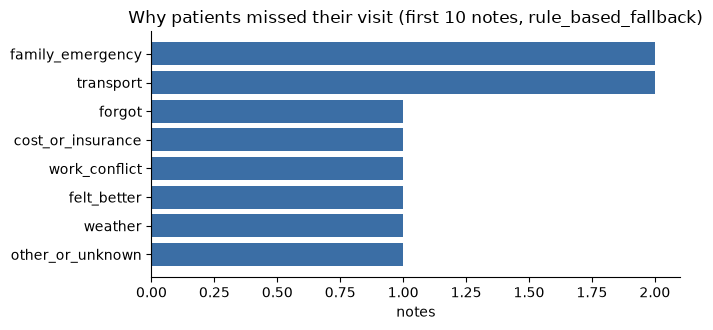

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.4))
counts = structured["primary_reason"].value_counts().sort_values()
ax.barh(counts.index, counts.values, color="#3b6ea5")
ax.set(title=f"Why patients missed their visit (first 10 notes, {SOURCE})", xlabel="notes")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "figures" / "04_noshow_reasons.png", dpi=130, bbox_inches="tight")

## 4. Combine AI findings with ML risk scores
- **AI findings** tell us *why* the patient missed and what they want.
- **ML risk score (Part 3)** tells us how likely this patient profile is to miss again, i.e. how much safety-net the next booking needs. (These notes concern appointments that were already missed, so the booking-time risk score is used as a proxy for the patient's reliability.)

Priority rules (transparent on purpose, so front-desk managers can challenge them):
| Priority | Rule |
|---|---|
| **P1 – call today** | patient has an urgent medical concern |
| **P2** | wants to reschedule **and** risk band is High |
| **P3** | wants to reschedule (Medium / Low risk) |
| **P4** | does not want to rebook **but** risk is High → try to re-engage |
| **P5** | does not want to rebook, lower risk → log the reason and close |

In [8]:
risk = pd.read_csv(OUT / "risk_scores.csv")
appts = pd.read_csv(DATA / "Appointments_clean.csv", usecols=["appointment_id", "lead_days", "previous_no_shows", "sms_received", "specialty"])
combined = (structured.merge(risk[["appointment_id", "clinic", "risk_score", "risk_band"]], on="appointment_id", how="left")
                      .merge(appts, on="appointment_id", how="left"))
assert combined["risk_score"].notna().all(), "every note must match a scored appointment"

ACTION_BY_REASON = {
    "transport": "Offer a slot near public transport or a video consult, and send directions with the confirmation.",
    "work_conflict": "Offer early-morning, evening or weekend slots that fit working hours.",
    "forgot": "Rebook with a short lead time and add a call or SMS reminder the day before.",
    "felt_better": "Ask the patient to call back if symptoms return; no new slot needed now.",
    "cost_or_insurance": "Have billing explain the fee and insurance cover BEFORE offering a new slot.",
    "illness": "Rebook for after recovery and check whether a clinical follow-up is needed.",
    "family_emergency": "Make a compassionate call and keep rebooking fully flexible.",
    "weather": "Offer an early-morning slot and send a weather-aware reminder.",
    "childcare": "Offer slots outside school-run hours or on Saturday.",
    "other_or_unknown": "Make a second contact attempt by SMS or call to find out why.",
}

def priority(r):
    if r["urgent_medical_concern"]:
        return "P1 - call today"
    if r["wants_to_reschedule"]:
        return "P2 - rebook now" if r["risk_band"] == "High" else "P3 - rebook"
    return "P4 - re-engage" if r["risk_band"] == "High" else "P5 - log & close"

def recommendation(r):
    steps = []
    if r["urgent_medical_concern"]:
        steps.append("Clinical call-back TODAY - patient may need urgent care.")
    steps.append(ACTION_BY_REASON[r["primary_reason"]])
    if r["wants_to_reschedule"]:
        if r["preferred_time"] != "no_preference":
            steps.append(f"Patient prefers {r['preferred_time']} slots.")
        if r["risk_band"] == "High":
            steps.append("High no-show risk: confirm by phone 48 h before AND SMS the day before; keep booking lead time under 7 days.")
        elif r["risk_band"] == "Medium":
            steps.append("Medium risk: send an SMS reminder the day before.")
    elif r["risk_band"] == "High":
        steps.append("High-risk profile and no new booking: schedule one friendly check-in call in ~2 weeks instead of closing the case.")
    return " ".join(steps)

combined["priority"] = combined.apply(priority, axis=1)
combined["recommended_action"] = combined.apply(recommendation, axis=1)
final = combined.sort_values(["priority", "risk_score"], ascending=[True, False])[
    ["priority", "appointment_id", "clinic", "risk_score", "risk_band", "primary_reason", "wants_to_reschedule",
     "preferred_time", "patient_sentiment", "urgent_medical_concern", "recommended_action", "extraction_source"]]
final.to_csv(OUT / "front_desk_recommendations.csv", index=False)
final[["priority", "appointment_id", "clinic", "risk_score", "risk_band", "primary_reason", "wants_to_reschedule"]]

,priority,appointment_id,clinic,risk_score,risk_band,primary_reason,wants_to_reschedule
8,P2 - rebook now,1009154,CareClick Dwarka,0.9786,High,cost_or_insurance,True
1,P2 - rebook now,1004878,CareClick Indiranagar,0.8679,High,transport,True
4,P2 - rebook now,1005413,CareClick Andheri,0.8402,High,work_conflict,True
6,P2 - rebook now,1004342,CareClick Dwarka,0.6917,High,transport,True
9,P3 - rebook,1000966,CareClick Indiranagar,0.6060,Medium,forgot,True
2,P3 - rebook,1009978,CareClick Indiranagar,0.4713,Low,family_emergency,True
0,P3 - rebook,1000783,CareClick Andheri,0.2664,Low,weather,True
5,P4 - re-engage,1000801,CareClick T Nagar,0.8361,High,felt_better,False
3,P5 - log & close,1000291,CareClick Whitefield,0.5982,Medium,other_or_unknown,False
7,P5 - log & close,1010176,CareClick Indiranagar,0.4512,Low,family_emergency,False


### The call list in full

In [9]:
for _, r in final.iterrows():
    print(f"[{r['priority']}] appt {r['appointment_id']} · {r['clinic']} · risk {r['risk_score']:.2f} ({r['risk_band']}) · reason: {r['primary_reason']}")
    print(f"    -> {r['recommended_action']}\n")

[P2 - rebook now] appt 1009154 · CareClick Dwarka · risk 0.98 (High) · reason: cost_or_insurance
    -> Have billing explain the fee and insurance cover BEFORE offering a new slot. High no-show risk: confirm by phone 48 h before AND SMS the day before; keep booking lead time under 7 days.

[P2 - rebook now] appt 1004878 · CareClick Indiranagar · risk 0.87 (High) · reason: transport
    -> Offer a slot near public transport or a video consult, and send directions with the confirmation. High no-show risk: confirm by phone 48 h before AND SMS the day before; keep booking lead time under 7 days.

[P2 - rebook now] appt 1005413 · CareClick Andheri · risk 0.84 (High) · reason: work_conflict
    -> Offer early-morning, evening or weekend slots that fit working hours. Patient prefers evening slots. High no-show risk: confirm by phone 48 h before AND SMS the day before; keep booking lead time under 7 days.

[P2 - rebook now] appt 1004342 · CareClick Dwarka · risk 0.69 (High) · reason: transport

## 5. Summary

In [10]:
print(f"Engine used: {SOURCE}")
print(f"Notes structured: {len(structured)} | priorities: {final['priority'].value_counts().sort_index().to_dict()}")
print("Top reasons:", structured["primary_reason"].value_counts().head(3).to_dict())
print("Saved: outputs/followup_notes_structured.csv, outputs/front_desk_recommendations.csv")
if not USE_GEMINI:
    print("\nNOTE: these results come from the rule-based fallback. Add GEMINI_API_KEY to .env and re-run to use Gemini.")

Engine used: rule_based_fallback
Notes structured: 10 | priorities: {'P2 - rebook now': 4, 'P3 - rebook': 3, 'P4 - re-engage': 1, 'P5 - log & close': 2}
Top reasons: {'transport': 2, 'family_emergency': 2, 'weather': 1}
Saved: outputs/followup_notes_structured.csv, outputs/front_desk_recommendations.csv

NOTE: these results come from the rule-based fallback. Add GEMINI_API_KEY to .env and re-run to use Gemini.
